
# Binary Logistic Regression

# 03 - Mini-Batch Gradient Descent

### Dataset
Breast Cancer Wisconsin Diagnostic Dataset

### Model
Binary Logistic Regression

### Optimization Method
Mini-Batch Gradient Descent (Batch Size = 32)

### Training Configuration
- Learning Rate: 0.01
- Maximum Epochs: 300
- Batch Size: 32
- Early Stopping with Best Model Weights Restoration

### Evaluation
Accuracy, Precision, Recall, F1-Score,
Confusion Matrix, ROC-AUC, and Log Loss.


In [1]:

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



/kaggle/input/datasets/erdemtaha/cancer-data/Cancer_Data.csv


In [2]:
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve,
    log_loss
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully.")
print("PyTorch version:", torch.__version__)


Libraries imported successfully.
PyTorch version: 2.11.0+cpu


In [3]:
df = pd.read_csv(
    "/kaggle/input/datasets/erdemtaha/cancer-data/Cancer_Data.csv"
)

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Number of rows: 569
Number of columns: 33

Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean    

In [5]:

display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,569.0,NaN,NaN,NaN,30371831.432337,125020585.612224,8670.0,869218.0,906024.0,8813129.0,911320502.0
diagnosis,569,2,B,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
radius_mean,569.0,NaN,NaN,NaN,14.127292,3.524049,6.981,11.7,13.37,15.78,28.11
texture_mean,569.0,NaN,NaN,NaN,19.289649,4.301036,9.71,16.17,18.84,21.8,39.28
perimeter_mean,569.0,NaN,NaN,NaN,91.969033,24.298981,43.79,75.17,86.24,104.1,188.5
area_mean,569.0,NaN,NaN,NaN,654.889104,351.914129,143.5,420.3,551.1,782.7,2501.0
smoothness_mean,569.0,NaN,NaN,NaN,0.09636,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
compactness_mean,569.0,NaN,NaN,NaN,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
concavity_mean,569.0,NaN,NaN,NaN,0.088799,0.07972,0.0,0.02956,0.06154,0.1307,0.4268
concave points_mean,569.0,NaN,NaN,NaN,0.048919,0.038803,0.0,0.02031,0.0335,0.074,0.2012


In [6]:
missing_count = df.isnull().sum()

missing_percentage = (df.isnull().mean() * 100).round(2)

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

print("Total Missing Values:", missing_count.sum())

print("\nColumns with Missing Values:")

display(
    missing_report[
        missing_report["Missing Count"] > 0
    ]
)

Total Missing Values: 569

Columns with Missing Values:


,Missing Count,Missing Percentage (%)
Unnamed: 32,569,100.0


In [7]:

df = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

df = df.drop_duplicates().copy()

df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

if df["diagnosis"].isnull().any():
    raise ValueError(
        "Unexpected target values found."
    )

print("Cleaned dataset shape:", df.shape)

display(df.head())


Cleaned dataset shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Class counts:
diagnosis
0    357
1    212
Name: count, dtype: int64

Class percentages:
diagnosis
0    62.741652
1    37.258348
Name: proportion, dtype: float64


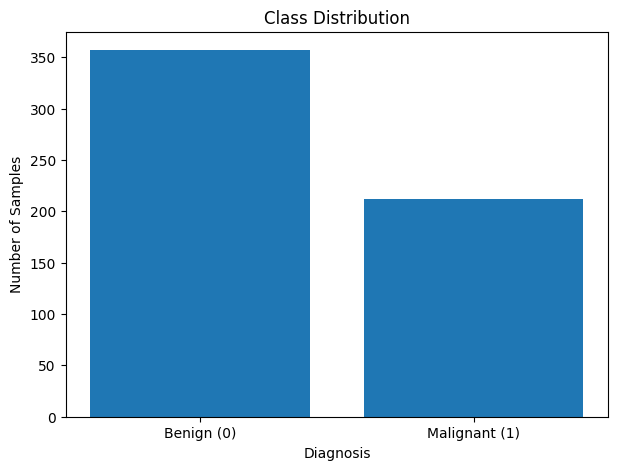

In [8]:

class_counts = (
    df["diagnosis"]
    .value_counts()
    .sort_index()
)

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(
    df["diagnosis"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Benign (0)", "Malignant (1)"],
    class_counts.values
)

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

plt.show()


In [9]:

X = df.drop(columns=["diagnosis"])

y = df["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumber of features:", X.shape[1])
print("Target classes:", sorted(y.unique()))


Features shape: (569, 30)
Target shape: (569,)

Number of features: 30
Target classes: [np.int64(0), np.int64(1)]


In [10]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 398
Validation samples: 85
Testing samples: 86


In [11]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

print(
    "Training means:",
    np.round(X_train_scaled.mean(axis=0)[:5], 3)
)

print(
    "Training standard deviations:",
    np.round(X_train_scaled.std(axis=0)[:5], 3)
)


Scaling completed.
Training means: [ 0. -0.  0.  0. -0.]
Training standard deviations: [1. 1. 1. 1. 1.]


In [12]:

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

print("Training features:", X_train_tensor.shape)
print("Training labels:", y_train_tensor.shape)


Training features: torch.Size([398, 30])
Training labels: torch.Size([398, 1])


In [13]:

class LogisticRegressionModel(nn.Module):

    def __init__(self, input_features):
        super().__init__()

        self.linear = nn.Linear(
            input_features,
            1
        )

    def forward(self, x):
        logits = self.linear(x)
        return logits


input_features = X_train_tensor.shape[1]

torch.manual_seed(SEED)

model = LogisticRegressionModel(input_features)

print(model)


LogisticRegressionModel(
  (linear): Linear(in_features=30, out_features=1, bias=True)
)


In [14]:

criterion = nn.BCEWithLogitsLoss()

print("Loss function initialized successfully.")


Loss function initialized successfully.


In [15]:

OPTIMIZER_NAME = "Mini-Batch Gradient Descent"

LEARNING_RATE = 0.01
EPOCHS = 300
BATCH_SIZE = 32

PATIENCE = 20
MIN_DELTA = 0.0001

torch.manual_seed(SEED)

model = LogisticRegressionModel(input_features)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE
)

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

print("Optimizer:", OPTIMIZER_NAME)
print("Learning Rate:", LEARNING_RATE)
print("Maximum Epochs:", EPOCHS)
print("Batch Size:", train_loader.batch_size)
print("Patience:", PATIENCE)


Optimizer: Mini-Batch Gradient Descent
Learning Rate: 0.01
Maximum Epochs: 300
Batch Size: 32
Patience: 20


In [16]:

import copy

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

patience_counter = 0

start_time = time.perf_counter()

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    model.eval()

    with torch.no_grad():

        train_logits = model(X_train_tensor)

        train_loss = criterion(
            train_logits,
            y_train_tensor
        )

        val_logits = model(X_val_tensor)

        val_loss = criterion(
            val_logits,
            y_val_tensor
        )

    current_train_loss = train_loss.item()
    current_val_loss = val_loss.item()

    train_losses.append(current_train_loss)
    val_losses.append(current_val_loss)

    if current_val_loss < best_val_loss - MIN_DELTA:

        best_val_loss = current_val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {current_train_loss:.4f} | "
            f"Validation Loss: {current_val_loss:.4f}"
        )

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch + 1}"
        )

        break

training_time = time.perf_counter() - start_time

epochs_trained = len(train_losses)

if best_model_state is None:
    raise RuntimeError("No best model weights were saved.")

model.load_state_dict(best_model_state)
model.eval()

print("\nTraining completed.")
print("Best model weights restored successfully.")
print("Epochs Trained:", epochs_trained)
print("Best Epoch:", best_epoch)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.4f} seconds")


Epoch 10/300 | Train Loss: 0.2335 | Validation Loss: 0.2360
Epoch 20/300 | Train Loss: 0.1736 | Validation Loss: 0.1793
Epoch 30/300 | Train Loss: 0.1474 | Validation Loss: 0.1532
Epoch 40/300 | Train Loss: 0.1323 | Validation Loss: 0.1376
Epoch 50/300 | Train Loss: 0.1223 | Validation Loss: 0.1269
Epoch 60/300 | Train Loss: 0.1151 | Validation Loss: 0.1191
Epoch 70/300 | Train Loss: 0.1096 | Validation Loss: 0.1130
Epoch 80/300 | Train Loss: 0.1052 | Validation Loss: 0.1082
Epoch 90/300 | Train Loss: 0.1017 | Validation Loss: 0.1043
Epoch 100/300 | Train Loss: 0.0988 | Validation Loss: 0.1011
Epoch 110/300 | Train Loss: 0.0963 | Validation Loss: 0.0985
Epoch 120/300 | Train Loss: 0.0941 | Validation Loss: 0.0962
Epoch 130/300 | Train Loss: 0.0921 | Validation Loss: 0.0940
Epoch 140/300 | Train Loss: 0.0904 | Validation Loss: 0.0922
Epoch 150/300 | Train Loss: 0.0889 | Validation Loss: 0.0907
Epoch 160/300 | Train Loss: 0.0875 | Validation Loss: 0.0893
Epoch 170/300 | Train Loss: 0.086

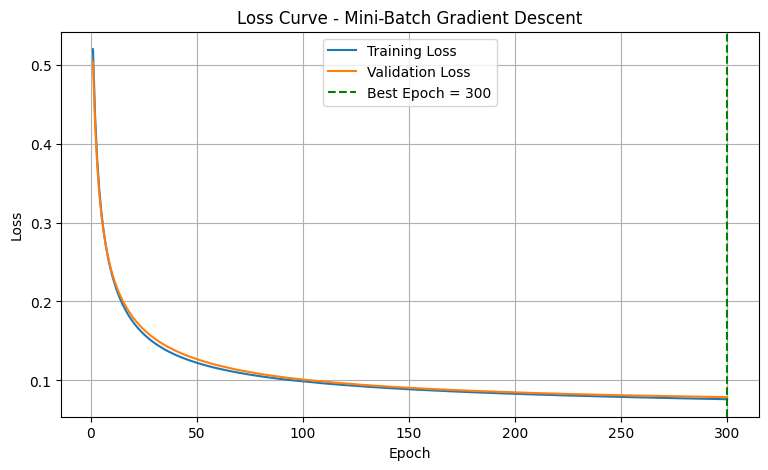

In [17]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs_trained + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, epochs_trained + 1),
    val_losses,
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    color="green",
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    f"Loss Curve - {OPTIMIZER_NAME}"
)

plt.legend()
plt.grid(True)
plt.show()


In [18]:

model.eval()

with torch.no_grad():

    test_logits = model(X_test_tensor)

    test_probabilities = torch.sigmoid(
        test_logits
    )

    test_predictions = (
        test_probabilities >= 0.5
    ).int()

y_true = y_test_tensor.numpy().ravel().astype(int)

y_pred = test_predictions.numpy().ravel()

y_prob = test_probabilities.numpy().ravel()

print("Actual Labels:", y_true[:10])
print("Predicted Labels:", y_pred[:10])
print("Predicted Probabilities:", y_prob[:10])


Actual Labels: [1 0 0 0 0 1 0 1 0 0]
Predicted Labels: [1 0 0 0 0 1 0 1 0 0]
Predicted Probabilities: [9.9999821e-01 9.3607593e-04 2.6211166e-03 2.8218855e-03 2.8677810e-02
 9.7958881e-01 3.2790438e-03 1.0000000e+00 1.4019107e-04 3.7314564e-03]


In [19]:

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

roc_auc = roc_auc_score(
    y_true, y_prob
)

test_log_loss = log_loss(
    y_true,
    y_prob,
    labels=[0, 1]
)

print("Evaluation Results")
print("-" * 40)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"Log Loss:  {test_log_loss:.4f}")


Evaluation Results
----------------------------------------
Accuracy:  0.9884
Precision: 1.0000
Recall:    0.9688
F1-Score:  0.9841
ROC-AUC:   1.0000
Log Loss:  0.0551


In [20]:

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Benign",
            "Malignant"
        ],
        zero_division=0
    )
)


              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        54
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86



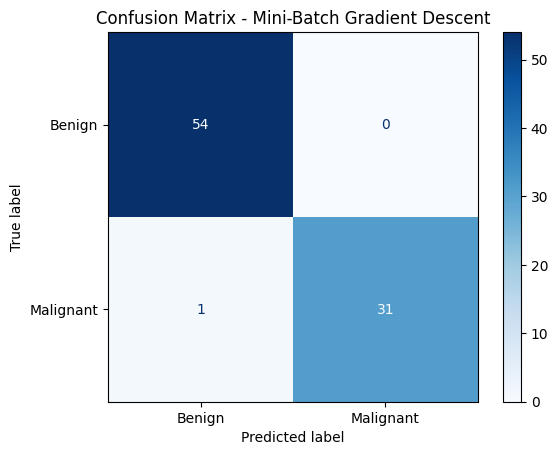

True Negatives: 54
False Positives: 0
False Negatives: 1
True Positives: 31


In [21]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")

plt.title(
    f"Confusion Matrix - {OPTIMIZER_NAME}"
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


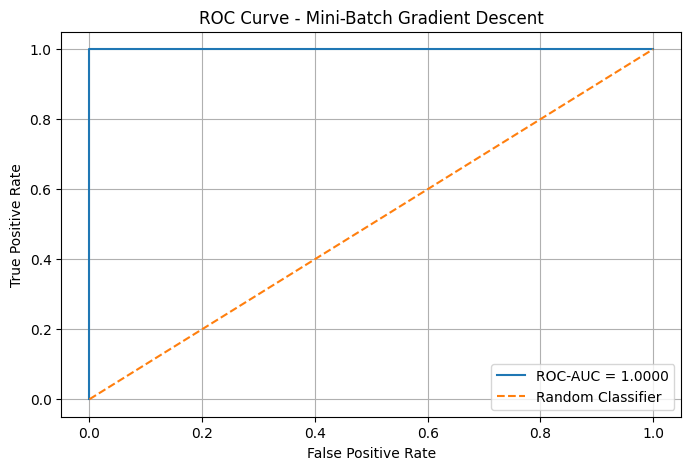

In [22]:

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve - {OPTIMIZER_NAME}"
)

plt.legend()
plt.grid(True)
plt.show()


In [23]:

results = pd.DataFrame([{
    "Optimizer": OPTIMIZER_NAME,
    "Max Epochs": EPOCHS,
    "Epochs Trained": epochs_trained,
    "Best Epoch": best_epoch,
    "Learning Rate": LEARNING_RATE,
    "Batch Size": train_loader.batch_size,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "ROC-AUC": roc_auc,
    "Log Loss": test_log_loss,
    "Training Time": training_time,
    "Final Train Loss": train_losses[-1],
    "Final Validation Loss": val_losses[-1],
    "Best Validation Loss": best_val_loss,
    "Selected Train Loss": train_losses[best_epoch - 1],
    "Selected Validation Loss": val_losses[best_epoch - 1]
}])

display(results.round(4))


,Optimizer,Max Epochs,Epochs Trained,Best Epoch,Learning Rate,Batch Size,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Log Loss,Training Time,Final Train Loss,Final Validation Loss,Best Validation Loss,Selected Train Loss,Selected Validation Loss
0,Mini-Batch Gradient Descent,300,300,300,0.01,32,0.9884,1.0,0.9688,0.9841,1.0,0.0551,3.1883,0.0762,0.0788,0.0788,0.0762,0.0788


In [24]:

results.to_csv(
    "/kaggle/working/mini_batch_gd_results.csv",
    index=False
)

print("Mini-Batch GD results saved successfully.")


Mini-Batch GD results saved successfully.
